<div style="background-color:#a7e8d9; padding: 20px; border-radius: 10px; box-shadow: 0 2px 4px 0 rgba(0, 0, 0, 0.1);">
    <h1 style="font-size:24px; font-family:calibri; color:#141140;"><b>🚀 YOLO: The Real-Time Object Detection Revolution</b></h1>
    <p style="font-size:20px; font-family:calibri; line-height: 1.5em; text-indent: 20px;">
        <strong>YOLO</strong>, short for "<strong>You Only Look Once</strong>", revolutionizes object detection in computer vision by offering a fast and streamlined approach. It uniquely simplifies the detection process, treating it as a single-step task that combines object localization and classification. This innovative method allows YOLO to process images and videos in real-time with high accuracy. The latest version, <strong>YOLOv8</strong>, further enhances this technology, adeptly tackling challenges in object detection and image segmentation. YOLO's real-time capabilities make it a standout choice for applications needing rapid and precise object identification.
    </p>
</div>


<div style="background-color:#eae8fa; padding: 20px; border-radius: 10px; box-shadow: 0 2px 4px 0 rgba(0, 0, 0, 0.1);">
    <h1 style="font-size:24px; font-family:calibri; color:#141140;"><b>🚦 Traffic Density Estimation Project Overview</b></h1>
    <p style="font-size:20px; font-family:calibri; line-height: 1.5em; text-indent: 20px;">
        Leveraging YOLO's real-time detection capabilities, this project focuses on <strong>Traffic Density Estimation</strong>, a vital component in urban and traffic management. The goal is to count vehicles within a specific area in each frame to assess traffic density. This valuable data aids in identifying peak traffic periods, congested zones, and assists in urban planning. Through this project, we aim to develop a comprehensive toolset that provides detailed insights into traffic flow and patterns, enhancing traffic management and city planning strategies.
    </p>
</div>


<div style="background-color:#eae8fa; padding: 20px; border-radius: 10px; box-shadow: 0 2px 4px 0 rgba(0, 0, 0, 0.1);">
    <h1 style="font-size:24px; font-family:calibri; color:#141140;"><b>🎯 Project Objectives</b></h1>
    <ul style="font-size:20px; font-family:calibri; line-height: 1.5em;">
        <li><strong>YOLOv8 Model Selection and Initial Assessment:</strong> Starting with YOLOv8's pre-trained model selection, assessing its initial performance on COCO dataset for vehicle detection.</li>
        <li><strong>Specialized Vehicle Dataset Preparation:</strong> Curating and annotating a vehicle-specific dataset to refine the model's detection capabilities for diverse vehicle types.</li>
        <li><strong>Model Fine-Tuning for Enhanced Vehicle Detection:</strong> Employing transfer learning to fine-tune the YOLOv8 model, focusing on vehicle detection from aerial perspectives for improved precision and recall.</li>
        <li><strong>Comprehensive Model Performance Evaluation:</strong> Analyzing learning curves, evaluating confusion matrix, and assessing performance metrics to validate the model's accuracy and generalization capabilities.</li>
        <li><strong>Inference and Generalization on Test Data:</strong> Testing the model's generalization on validation images, an unseen test image, and a test video to demonstrate its practical application and effectiveness.</li>
        <li><strong>Real-Time Traffic Density Estimation:</strong> Implementing an algorithm to estimate traffic density by counting vehicles and analyzing traffic intensity in real-time on test video data.</li>
        <li><strong>Cross-Platform Model Deployment Preparation:</strong> Exporting the fine-tuned model in ONNX format for versatile use across different platforms and environments.</li>
    </ul>
</div>


# Import Modules

In [1]:
import warnings
warnings.filterwarnings('ignore')
!pip install ultralytics
# Import necessary libraries
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import yaml
from PIL import Image
from ultralytics import YOLO
from IPython.display import Video

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 29.9 MB/s eta 0:00:0000:01
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [2]:
# Configure the visual appearance of seaborn plots
sns.set(rc={'axes.facecolor': '#eae8fa'}, style='darkgrid')

# Load Pretrained Model

In [3]:
# Loading YOLO Pretrained model
model = YOLO('yolov8n.pt')

# Path to image file

In [11]:
import os

# Find the exact folder name Kaggle assigned
for item in os.listdir('/kaggle/input'):
    print(item)

Vehicle_Detection_Image_Dataset


In [10]:
import os

dataset_dir = '/kaggle/input/Vehicle_Detection_Image_Dataset'

for f in os.listdir(dataset_dir):
    print(f)

README.dataset.txt
README.roboflow.txt
data.yaml
valid
sample_video.mp4
sample_image.jpg
train


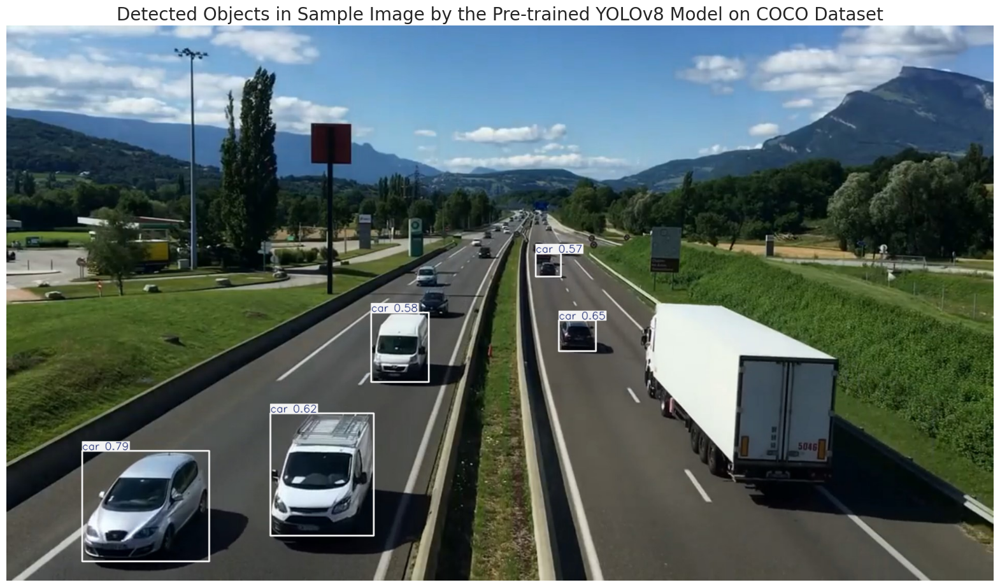

In [12]:
# Path to the image file
image_path = '/kaggle/input/Vehicle_Detection_Image_Dataset/sample_image.jpg'
# Perform inference on the provided image(s)
results = model.predict(source=image_path, 
                        imgsz=640,
                        verbose=False,# Resize image to 640x640 (the size pf images the model was trained on)
                        conf=0.5)   # Confidence threshold: 50% (only detections above 50% confidence will be considered)

# Annotate and convert image to numpy array
sample_image = results[0].plot(line_width=2)

# Convert the color of the image from BGR to RGB for correct color representation in matplotlib
sample_image = cv2.cvtColor(sample_image, cv2.COLOR_BGR2RGB)

# Display annotated image
plt.figure(figsize=(20,15))
plt.imshow(sample_image)
plt.title('Detected Objects in Sample Image by the Pre-trained YOLOv8 Model on COCO Dataset', fontsize=20)
plt.axis('off')
plt.show()

<div style="background-color:#eae8fa; padding: 20px; border-radius: 10px; box-shadow: 0 2px 4px 0 rgba(0, 0, 0, 0.1);">
    <h2 style="font-size:22px; font-family:calibri; color:#141140;"><b>🔍 Pre-trained Model Detection Analysis</b></h2>
    <p style="font-size:18px; font-family:calibri; line-height: 1.5em; text-indent: 20px;">
        In our sample image, the pre-trained model missed the detectable truck and car that were clearly visible. A model pre-trained on a dataset with a broad range of classes, like COCO's 80 different categories, may not perform as well on a specific subset of those categories due to the diversity of objects it has been trained to recognize. If we fine-tune this model on a specialized dataset that focuses solely on vehicles, it can learn to detect various types of vehicles more accurately. Fine-tuning on a vehicle-specific dataset allows the model to become more specialized, adjusting the weights to be more sensitive to features specific to vehicles. As a result, the model's mean Average Precision (mAP) for vehicle detection could improve because it's being optimized on a narrower, more relevant range of classes for our specific application. Fine-tuning also helps the model generalize better for vehicle detection tasks, potentially reducing false negatives (like missing a detectable truck) and improving overall detection performance.
    </p>
</div>


In [14]:
# Define the dataset_path
dataset_path = '/kaggle/input/Vehicle_Detection_Image_Dataset'

# Set the path YAML file
yaml_file_path = os.path.join(dataset_path, 'data.yaml')

# Load and print the contents of the YAML file
with open(yaml_file_path, 'r') as file:
    yaml_content = yaml.load(file, Loader = yaml.FullLoader)
    print(yaml.dump(yaml_content, default_flow_style=False))

names:
- Vehicle
nc: 1
roboflow:
  license: CC BY 4.0
  project: vehicle_detection_yolov8
  url: https://universe.roboflow.com/farzad/vehicle_detection_yolov8/dataset/3
  version: 3
  workspace: farzad
train: ../train/images
val: ../valid/images



<div style="background-color:#eae8fa; padding: 20px; border-radius: 10px; box-shadow: 0 2px 4px 0 rgba(0, 0, 0, 0.1);">
    <h2 style="font-size:22px; font-family:calibri; color:#141140;"><b>🗂️ Understanding the data.yaml File</b></h2>
    <p style="font-size:18px; font-family:calibri; line-height: 1.5em; text-indent: 20px;">
        As I previously mentioned, the 'data.yaml' file is a key part of setting up our model. It points out where to find the training and validation images and tells the model that we're focusing on just one class, named 'Vehicle'. This file is essential for making sure our Ultralytics YOLOv8 model learns from our specific dataset, as it guides the model to understand exactly what it needs to look for and where.
    </p>
</div>


In [15]:
# Set paths for trainig and validation images sets
trian_image_path = os.path.join(dataset_path, 'train', 'images')
validation_image_path = os.path.join(dataset_path, 'valid', 'images')

# Initialize counters for the number of images
num_trian_images = 0
num_valid_images = 0

# Initialize sets to hold the unique sizes of images
train_image_size = set()
valid_image_size = set()

# Check train images sizes and count
for filename in os.listdir(trian_image_path):
    if filename.endswith('.jpg'):
        num_trian_images += 1
        image_path = os.path.join(trian_image_path, filename)
        with Image.open(image_path) as img:
            train_image_size.add(img.size)
            
# Check validation images sizes and count
for filename in os.listdir(validation_image_path):
    if filename.endswith('.jpg'):
        num_valid_images +=1
        image_path = os.path.join(validation_image_path, filename)
        with Image.open(image_path) as img:
            valid_image_size.add(img.size)
            
            
# Print the resutls 
print(f"Number of training images:, {num_trian_images}")
print(f"Number of validation images: {num_valid_images}")

# Check if all images in training set have the same size
if len(train_image_size) == 1:
    print(f"All training images have the same size: {train_image_size.pop()}")
else:
    print("Training images have verying sizes.")
    
# Check if all images is validation set have same size
if len(valid_image_size) == 1:
    print(f"All validation images have the same size: {valid_image_size.pop()}")
    
else:
    print("Validation images have verying sizes")
    

Number of training images:, 536
Number of validation images: 90
All training images have the same size: (640, 640)
All validation images have the same size: (640, 640)


<div style="background-color:#eae8fa; padding: 20px; border-radius: 10px; box-shadow: 0 2px 4px 0 rgba(0, 0, 0, 0.1);">
    <h2 style="font-size:22px; font-family:calibri; color:#141140;"><b>📊 Dataset Analysis Insights</b></h2>
    <p style="font-size:18px; font-family:calibri; line-height: 1.5em; text-indent: 20px;">
        The dataset for our project consists of 536 training images and 90 validation images, all uniformly sized at 640x640 pixels. This size aligns with the benchmark standard for the YOLOv8 model, ensuring optimal accuracy and speed during model performance. The split ratio of approximately 85% for training and 15% for validation provides a substantial amount of data for model learning while retaining enough images for effective model validation.
    </p>
</div>

# Data Visualization

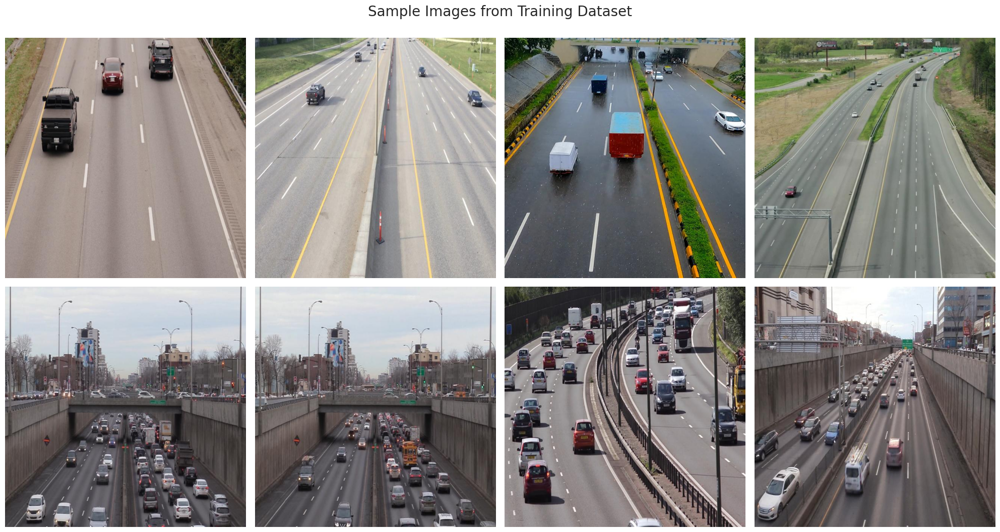

In [16]:
# List all jpg images in the directory

image_files = [file for file in os.listdir(trian_image_path) if file.endswith('.jpg')]

# Select 8 images as eqal intervals
num_images = len(image_files)
selected_images = [image_files[i] for i in range(0, num_images, num_images // 8)]

# Create a 2x4 subplot
fig,axes = plt.subplots(2,4,figsize=(20,11))

# Display each of the selected images
for ax, img_file in zip(axes.ravel(), selected_images):
    img_path =os.path.join(trian_image_path, img_file)
    image = Image.open(img_path)
    ax.imshow(image)
    ax.axis('off')
    
plt.suptitle('Sample Images from Training Dataset',fontsize=20)
plt.tight_layout()
plt.show()

# Fine tunning YOLOv8 model

In [17]:
# Train the model on out custome dataset
results = model.train(
    data = yaml_file_path,
    epochs = 100,
    imgsz=640,
    device=0,
    patience=50,
    batch = 32,
    optimizer='auto',
    lr0 = 0.0001,
    lrf = 0.1,
    dropout=0.1)

Ultralytics 8.4.21 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/Vehicle_Detection_Image_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.1, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=T

2026-03-09 07:00:50,943	INFO util.py:124 -- Outdated packages:
  ipywidgets==7.7.1 found, needs ipywidgets>=8
Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-03-09 07:00:51,676	INFO util.py:124 -- Outdated packages:
  ipywidgets==7.7.1 found, needs ipywidgets>=8
Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


Overriding model.yaml nc=80 with nc=1

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1    295424  ultralytics

<div style="background-color:#eae8fa; padding: 20px; border-radius: 10px; box-shadow: 0 2px 4px 0 rgba(0, 0, 0, 0.1);">
    <h2 style="font-size:22px; font-family:calibri; color:#141140;"><b>🌐 Integration of Weights & Biases (Wandb) with YOLOv8</b></h2>
    <p style="font-size:18px; font-family:calibri; line-height: 1.5em; text-indent: 20px;">
        Weights & Biases, known as <strong>wandb.ai</strong>, is an MLOps tool that works seamlessly with Ultralytics, including the YOLOv8 model. When we train our YOLOv8 model, <strong>wandb.ai</strong> helps to manage our machine learning experiments by monitoring the training process, logging important metrics, and saving outputs. It's like a dashboard where we can see how our model is learning, with all the details and visualizations to help us understand the training progress and results.
    </p>
    <p style="font-size:18px; font-family:calibri; line-height: 1.5em; text-indent: 20px;">
        <b>🔑 Providing the API Key</b><br>
        During the model training, an API key is required for Weights & Biases to track and store our model's data. We'll be prompted to sign up at <a href="https://wandb.ai/authorize">https://wandb.ai/authorize</a> to get this key. After signing up, we copy the API key provided and paste it back into our training setup. This key connects our training session to the Weights & Biases platform, allowing us to access all the great features for monitoring and evaluating our model.
    </p>
</div>


# Model Performance Evaluation

In [18]:
# Define the path to the Directory
post_training_files_path ='/kaggle/working/runs/detect/train'

# list the files in the directory
!ls {post_training_files_path}


BoxF1_curve.png			 labels.jpg	      train_batch1532.jpg
BoxPR_curve.png			 results.csv	      train_batch2.jpg
BoxP_curve.png			 results.png	      val_batch0_labels.jpg
BoxR_curve.png			 train_batch0.jpg     val_batch0_pred.jpg
args.yaml			 train_batch1.jpg     val_batch1_labels.jpg
confusion_matrix.png		 train_batch1530.jpg  val_batch1_pred.jpg
confusion_matrix_normalized.png  train_batch1531.jpg  weights


# Learning curve Analysis

In [19]:
# Construct the path to the best model weights file using os.path.join
best_model_path = os.path.join(post_training_files_path, 'weights/best.pt')

# Load the best model weights into the YOLO model
best_model = YOLO(best_model_path)

# Validate the best model using the validation set with default parameters
metrics = best_model.val(split='val')

Ultralytics 8.4.21 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 1.2±0.1 ms, read: 113.9±19.0 MB/s, size: 61.7 KB)
val: Scanning /kaggle/input/Vehicle_Detection_Image_Dataset/valid/labels... 90 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 90/90 634.8it/s 0.1s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/Vehicle_Detection_Image_Dataset/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.3s/it 7.9s0.3s
                   all         90        937      0.925      0.928      0.972       0.74
Speed: 4.5ms preprocess, 17.0ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /kaggle/working/runs/detect/val


In [23]:
# Define a function to plot learning curves for loss values
def plot_learning_curve(df, train_loss_col, val_loss_col, title):
    plt.figure(figsize=(12, 5))
    sns.lineplot(data=df, x='epoch', y=train_loss_col, label='Train Loss', color='#141140', linestyle='-', linewidth=2)
    sns.lineplot(data=df, x='epoch', y=val_loss_col, label='Validation Loss', color='orangered', linestyle='--', linewidth=2)
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

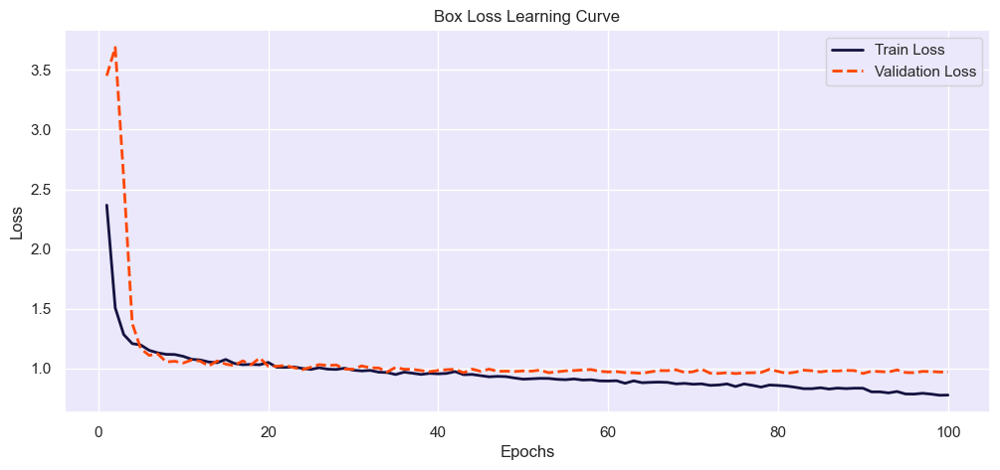

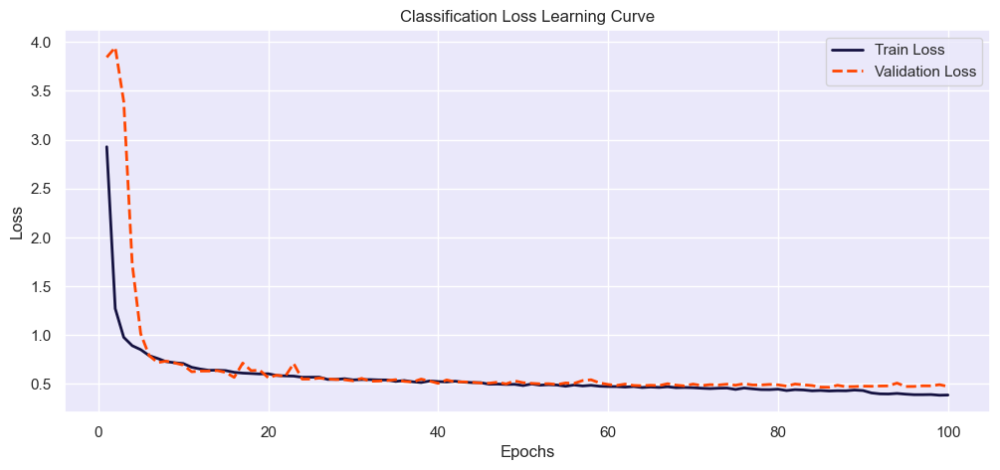

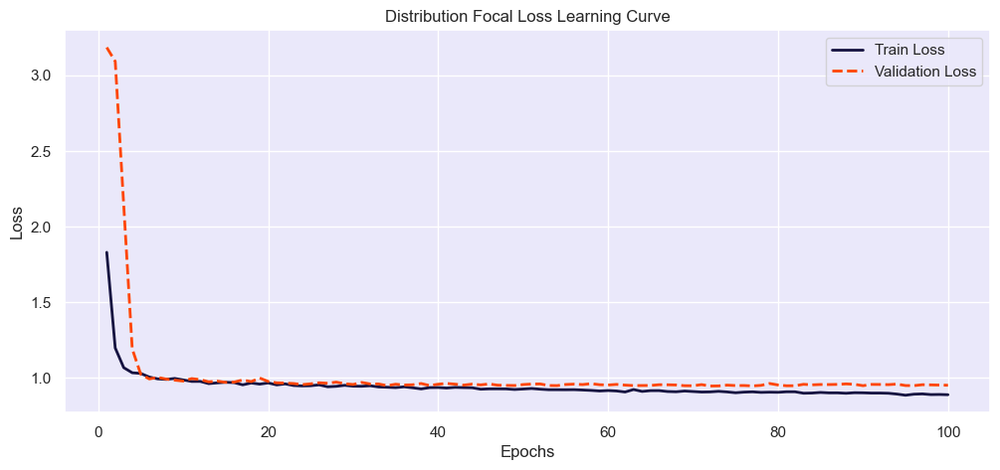

In [24]:
# Create the full file path for 'results.csv' using the directory path and file name
results_csv_path = os.path.join(post_training_files_path, 'results.csv')

# Load the CSV file from the constructed path into a pandas DataFrame
df = pd.read_csv(results_csv_path)

# Remove any leading whitespace from the column names
df.columns = df.columns.str.strip()

# Plot the learning curves for each loss
plot_learning_curve(df, 'train/box_loss', 'val/box_loss', 'Box Loss Learning Curve')
plot_learning_curve(df, 'train/cls_loss', 'val/cls_loss', 'Classification Loss Learning Curve')
plot_learning_curve(df, 'train/dfl_loss', 'val/dfl_loss', 'Distribution Focal Loss Learning Curve')

# Model Inferance and Generalization Assessment


image 1/1 /kaggle/input/Vehicle_Detection_Image_Dataset/valid/images/6_mp4-0_jpg.rf.9a055d040151678e04cb48a8bde76f55.jpg: 640x640 3 Vehicles, 9.8ms
Speed: 2.4ms preprocess, 9.8ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/Vehicle_Detection_Image_Dataset/valid/images/4_mp4-7_jpg.rf.439bc6176789cd7ca6bd686e23fc5ddf.jpg: 640x640 17 Vehicles, 5.7ms
Speed: 1.4ms preprocess, 5.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/Vehicle_Detection_Image_Dataset/valid/images/6_mp4-14_jpg.rf.a5099c3eeb2c707a2193c0efa467bb2a.jpg: 640x640 3 Vehicles, 6.0ms
Speed: 1.4ms preprocess, 6.0ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/Vehicle_Detection_Image_Dataset/valid/images/11_mp4-15_jpg.rf.b1bdb8b4864b5bed3c78f1a70e2dc011.jpg: 640x640 13 Vehicles, 5.5ms
Speed: 1.3ms preprocess, 5.5ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kag

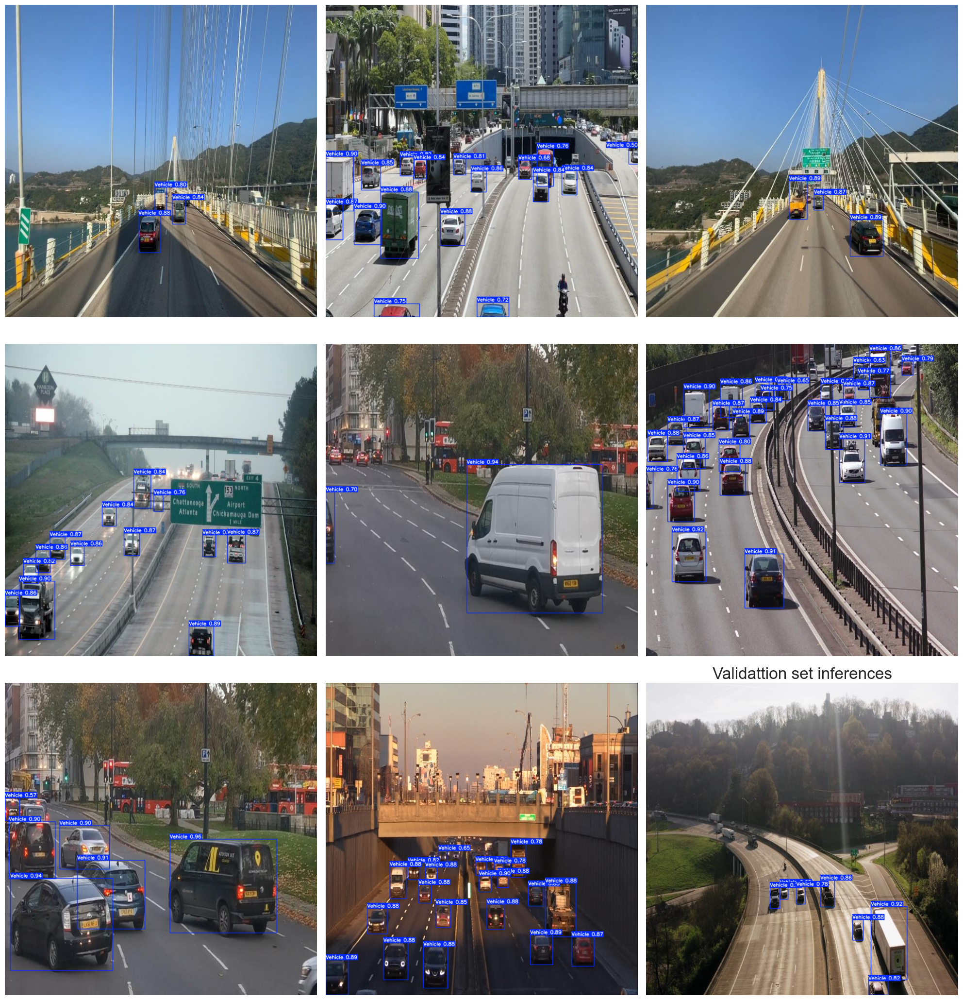

In [25]:
# Interface on validationset
valid_image_path = os.path.join(dataset_path, 'valid','images')

# list all jpg images in the directory
image_files = [file for file in os.listdir(valid_image_path) if file.endswith('.jpg')]

# select 9 images at equal intervals
num_images = len(image_files)
selected_images = [image_files[i] for i in range(0, num_images, num_images // 9)]

# Initailize the subplot
fig, axes = plt.subplots(3,3,figsize=(20,21))
plt.title('Validattion set inferences', fontsize=24)


# Perform inferences on each selected image and display it
for i, ax, in enumerate(axes.flatten()):
    image_path = os.path.join(valid_image_path, selected_images[i])
    results = best_model.predict(source = image_path, imgsz = 640, conf=0.5)
    annotated_image = results[0].plot(line_width=1)
    annotated_image_rgb =cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
    ax.imshow(annotated_image_rgb)
    ax.axis('off')
    
plt.tight_layout()
plt.show()

# Inference on an unseen test image


image 1/1 /kaggle/input/Vehicle_Detection_Image_Dataset/sample_image.jpg: 384x640 6 Vehicles, 11.7ms
Speed: 2.1ms preprocess, 11.7ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)


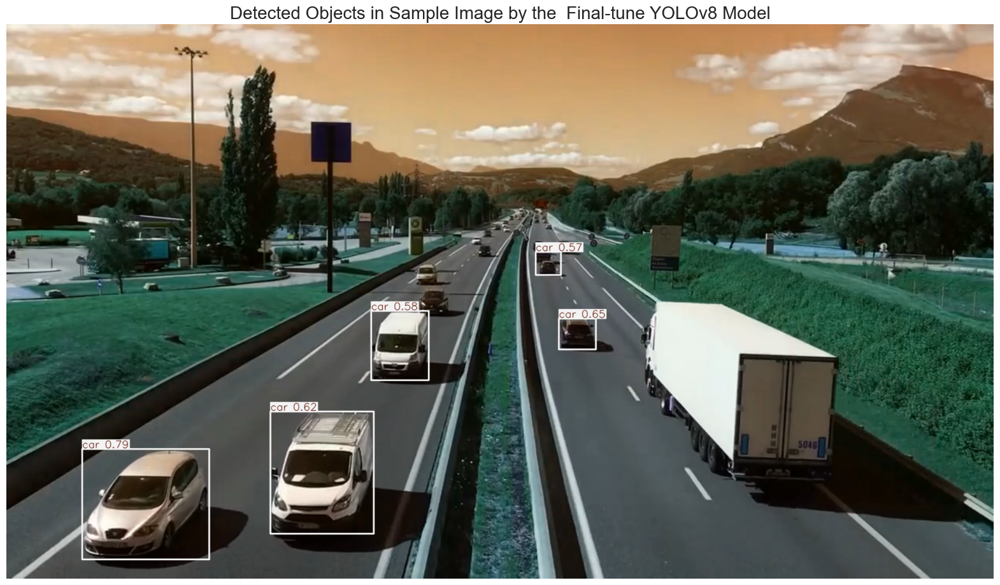

In [27]:
sample_image_path = '/kaggle/input/Vehicle_Detection_Image_Dataset/sample_image.jpg'

# Perform inference on the provided image using best model
results = best_model.predict(source=sample_image_path, imgsz=640,conf=0.7)

# Annotate and convert image to numpy array
smaple_image = results[0].plot(line_width=2)

# convert the color of the image from BGR to RGB for correct color representation in matplotlib
sample_image = cv2.cvtColor(sample_image, cv2.COLOR_BGR2RGB)

# Display annotated image
plt.figure(figsize=(20,15))
plt.imshow(sample_image)
plt.title('Detected Objects in Sample Image by the  Final-tune YOLOv8 Model', fontsize=20)
plt.axis('off')
plt.show()

In [29]:
# Define the path to the sample video in the dataset
dataset_video_path = '/kaggle/input/Vehicle_Detection_Image_Dataset/sample_video.mp4'

# Define the destination path in the working directory
video_path = '/kaggle/working/sample_video.mp4'

# Copy the video file from its original location in the dataset to the current working directory in Kaggle for further processing
shutil.copyfile(dataset_video_path, video_path)

# Initiate vehicle detection on the sample video using the best performing model and save the output
best_model.predict(source=video_path, save=True)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/601) /kaggle/working/sample_video.mp4: 384x640 3 Vehicles, 6.8ms
video 1/1 (frame 2/601) /kaggle/working/sample_video.mp4: 384x640 2 Vehicles, 6.8ms
video 1/1 (frame 3/601) /kaggle/working/sample_video.mp4: 384x640 2 Vehicles, 6.1ms
video 1/1 (frame 4/601) /kaggle/working/sample_video.mp4: 384x640 3 Vehicles, 6.2ms
video 1/1 (frame 5/601) /kaggle/working/sample_video.mp4: 384x640 3 Vehicles, 6.3ms
video 1/1 (frame 6/601) /kaggle/workin

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'Vehicle'}
 obb: None
 orig_img: array([[[252, 245, 242],
         [252, 245, 242],
         [252, 245, 242],
         ...,
         [210, 184, 166],
         [210, 184, 166],
         [210, 184, 166]],
 
        [[252, 245, 242],
         [252, 245, 242],
         [252, 245, 242],
         ...,
         [210, 184, 166],
         [210, 184, 166],
         [210, 184, 166]],
 
        [[254, 246, 241],
         [254, 246, 241],
         [254, 246, 241],
         ...,
         [210, 184, 166],
         [210, 184, 166],
         [210, 184, 166]],
 
        ...,
 
        [[ 94, 104, 103],
         [ 96, 106, 105],
         [101, 111, 110],
         ...,
         [ 94, 106, 111],
         [ 95, 107, 112],
         [ 97, 109, 114]],
 
        [[ 98, 108, 107],
         [103, 113, 112],
         [100, 110, 109],
         ...,
         [ 95, 10

In [32]:
# Convert the .avi video generated by the YOLOv8 prediction to .mp4 format for compatibility with notebook display
!ffmpeg -y -loglevel panic -i /kaggle/working/runs/detect/predict/sample_video.avi processed_sample_video.mp4

# Embed and display the processed sample video within the notebook
Video("processed_sample_video.mp4", embed=True, width=960)


# Real Time Traffic Intensity Esteminator

In [33]:
# Define the threshold for considering traffic as heavy
heavy_traffic_threshold = 10

# Define the vertices for the quadrilaterals
vertices1 = np.array([(465, 350), (609, 350), (510, 630), (2, 630)], dtype=np.int32)
vertices2 = np.array([(678, 350), (815, 350), (1203, 630), (743, 630)], dtype=np.int32)

# Define the vertical range for the slice and lane threshold
x1, x2 = 325, 635 
lane_threshold = 609

# Define the positions for the text annotations on the image
text_position_left_lane = (10, 50)
text_position_right_lane = (820, 50)
intensity_position_left_lane = (10, 100)
intensity_position_right_lane = (820, 100)

# Define font, scale, and colors for the annotations
font = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 1
font_color = (255, 255, 255)    # White color for text
background_color = (0, 0, 255)  # Red background for text
        
# Open the video
cap = cv2.VideoCapture('sample_video.mp4')

# Define the codec and create VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*'XVID')
out = cv2.VideoWriter('traffic_density_analysis.avi', fourcc, 20.0, (int(cap.get(3)), int(cap.get(4))))

# Read until video is completed
while cap.isOpened():
    # Capture frame-by-frame
    ret, frame = cap.read()
    if ret:
        # Create a copy of the original frame to modify
        detection_frame = frame.copy()
    
        # Black out the regions outside the specified vertical range
        detection_frame[:x1, :] = 0  # Black out from top to x1
        detection_frame[x2:, :] = 0  # Black out from x2 to the bottom of the frame
        
        # Perform inference on the modified frame
        results = best_model.predict(detection_frame, imgsz=640, conf=0.4)
        processed_frame = results[0].plot(line_width=1)
        
        # Restore the original top and bottom parts of the frame
        processed_frame[:x1, :] = frame[:x1, :].copy()
        processed_frame[x2:, :] = frame[x2:, :].copy()        
        
        # Draw the quadrilaterals on the processed frame
        cv2.polylines(processed_frame, [vertices1], isClosed=True, color=(0, 255, 0), thickness=2)
        cv2.polylines(processed_frame, [vertices2], isClosed=True, color=(255, 0, 0), thickness=2)
        
        # Retrieve the bounding boxes from the results
        bounding_boxes = results[0].boxes

        # Initialize counters for vehicles in each lane
        vehicles_in_left_lane = 0
        vehicles_in_right_lane = 0

        # Loop through each bounding box to count vehicles in each lane
        for box in bounding_boxes.xyxy:
            # Check if the vehicle is in the left lane based on the x-coordinate of the bounding box
            if box[0] < lane_threshold:
                vehicles_in_left_lane += 1
            else:
                vehicles_in_right_lane += 1
                
        # Determine the traffic intensity for the left lane
        traffic_intensity_left = "Heavy" if vehicles_in_left_lane > heavy_traffic_threshold else "Smooth"
        # Determine the traffic intensity for the right lane
        traffic_intensity_right = "Heavy" if vehicles_in_right_lane > heavy_traffic_threshold else "Smooth"


        # Add a background rectangle for the left lane vehicle count
        cv2.rectangle(processed_frame, (text_position_left_lane[0]-10, text_position_left_lane[1] - 25), 
                      (text_position_left_lane[0] + 460, text_position_left_lane[1] + 10), background_color, -1)

        # Add the vehicle count text on top of the rectangle for the left lane
        cv2.putText(processed_frame, f'Vehicles in Left Lane: {vehicles_in_left_lane}', text_position_left_lane, 
                    font, font_scale, font_color, 2, cv2.LINE_AA)

        # Add a background rectangle for the left lane traffic intensity
        cv2.rectangle(processed_frame, (intensity_position_left_lane[0]-10, intensity_position_left_lane[1] - 25), 
                      (intensity_position_left_lane[0] + 460, intensity_position_left_lane[1] + 10), background_color, -1)

        # Add the traffic intensity text on top of the rectangle for the left lane
        cv2.putText(processed_frame, f'Traffic Intensity: {traffic_intensity_left}', intensity_position_left_lane, 
                    font, font_scale, font_color, 2, cv2.LINE_AA)

        # Add a background rectangle for the right lane vehicle count
        cv2.rectangle(processed_frame, (text_position_right_lane[0]-10, text_position_right_lane[1] - 25), 
                      (text_position_right_lane[0] + 460, text_position_right_lane[1] + 10), background_color, -1)

        # Add the vehicle count text on top of the rectangle for the right lane
        cv2.putText(processed_frame, f'Vehicles in Right Lane: {vehicles_in_right_lane}', text_position_right_lane, 
                    font, font_scale, font_color, 2, cv2.LINE_AA)

        # Add a background rectangle for the right lane traffic intensity
        cv2.rectangle(processed_frame, (intensity_position_right_lane[0]-10, intensity_position_right_lane[1] - 25), 
                      (intensity_position_right_lane[0] + 460, intensity_position_right_lane[1] + 10), background_color, -1)

        # Add the traffic intensity text on top of the rectangle for the right lane
        cv2.putText(processed_frame, f'Traffic Intensity: {traffic_intensity_right}', intensity_position_right_lane, 
                    font, font_scale, font_color, 2, cv2.LINE_AA)

        # Write the processed frame to the output video
        out.write(processed_frame)
        
        # Uncomment the following 3 lines if running this code on a local machine to view the real-time processing results
        # cv2.imshow('Real-time Analysis', processed_frame)
        # if cv2.waitKey(1) & 0xFF == ord('q'):  # Press Q on keyboard to exit the loop
        #     break
    else:
        break

# Release the video capture and video write objects
cap.release()
out.release()

# Close all the frames
# cv2.destroyAllWindows()



0: 384x640 (no detections), 13.9ms
Speed: 3.6ms preprocess, 13.9ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 7.1ms
Speed: 1.8ms preprocess, 7.1ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 6.6ms
Speed: 2.6ms preprocess, 6.6ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 6.6ms
Speed: 2.4ms preprocess, 6.6ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 6.4ms
Speed: 1.6ms preprocess, 6.4ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 6.9ms
Speed: 1.6ms preprocess, 6.9ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 6.3ms
Speed: 1.9ms preprocess, 6.3ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 (no detections), 6.7ms
Speed: 2.1ms preprocess, 6.7ms inference, 0.6m

In [34]:
# Convert the .avi video generated by our traffic density estimation app to .mp4 format for compatibility with notebook display
!ffmpeg -y -loglevel panic -i /kaggle/working/traffic_density_analysis.avi traffic_density_analysis.mp4

# Embed and display the processed sample video within the notebook
Video("traffic_density_analysis.mp4", embed=True, width=960)